# Numerical results: crest surface of an anisotropic Airy field

In this notebook we illustrate the theorem *Expected crest surface area* of the paper on simulated Airy fields with an
anisotropic spectrum. Hence, the expected crest area depends on the angle direction $\theta$. The sections follow the
paragraphs of the section *Numerical results*.

All the simulation code is in the notebook. The Monte Carlo runs are saved in `data/`; the flag `USE_SAVED_DATA` in the next
cell chooses between loading them and running all the simulations from zero.

In [1]:
# True: load the Monte Carlo runs from data/ (the notebook runs in about 2 minutes).
# False: run all the Monte Carlo simulations from zero and save them in data/ (about 2 hours for Sections 4-5
# and 1.5 hours for Section 6). If a file of data/ is missing, that run is simulated in both cases.
USE_SAVED_DATA = True

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy.integrate import quad
from scipy.ndimage import map_coordinates
from scipy.optimize import brentq
from scipy.special import ellipe
from skimage.measure import find_contours, marching_cubes

os.makedirs("data", exist_ok=True)
os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9, "axes.titlesize": 9,
                     "axes.labelsize": 9, "legend.fontsize": 7.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.linewidth": 0.6, "savefig.bbox": "tight"})

## 1. Model construction

We take an affine image of the squared-exponential spectrum. Let $\mu\sim\mathcal N(0,I_2)$ and
$$\lambda=A\mu,\qquad A=R_{\phi_0}\operatorname{diag}(a_1,a_2)\,R_{\phi_0}^T,\qquad a_1=\tfrac32,\quad a_2=\tfrac23,\quad \phi_0=\tfrac\pi6,$$
where $R_{\phi_0}$ is the rotation of angle $\phi_0$. The matrix $A$ is symmetric and positive definite, with eigenvectors
$e_1=(\cos\phi_0,\sin\phi_0)^T$ (eigenvalue $a_1$) and $e_2=e_1^\perp$ (eigenvalue $a_2$). The wave-number spectrum is the density of $\lambda$,
$$f_A(\lambda)=\frac{1}{2\pi\det A}\,e^{-|A^{-1}\lambda|^2/2},\qquad \Gamma(x,y,0)=\mathbb E\bigl[\cos\langle A\mu,(x,y)^T\rangle\bigr]=e^{-|A(x,y)^T|^2/2}.$$
The map $p\mapsto Ap$ stretches the plane by $a_1$ along $e_1$ and shrinks it by $a_2$ along $e_2$: the field changes faster along $e_1$.
The frequency $\omega(\lambda)=|A\mu|^{1/2}$ also depends on $A$.

Let $\alpha=\theta-\phi_0$ be the angle between $u_\theta$ and $e_1$. The vector $(\langle u_\theta,\lambda\rangle,\langle u_\theta^\perp,\lambda\rangle)$
is centred Gaussian with covariance
$$c_{11}=a_1^2\cos^2\alpha+a_2^2\sin^2\alpha,\qquad c_{22}=a_1^2\sin^2\alpha+a_2^2\cos^2\alpha,\qquad c_{12}=(a_2^2-a_1^2)\sin\alpha\cos\alpha,$$
and Isserlis' theorem gives the spatial moments $\widetilde m_{2,0,0}=c_{11}$, $\widetilde m_{1,1,0}=c_{12}$, $\widetilde m_{0,2,0}=c_{22}$,
$\widetilde m_{4,0,0}=3c_{11}^2$, $\widetilde m_{3,1,0}=3c_{11}c_{12}$, $\widetilde m_{2,2,0}=c_{11}c_{22}+2c_{12}^2$. The moments with $i+j$ odd vanish.
With $\rho(\psi)=(a_1^2\cos^2\psi+a_2^2\sin^2\psi)^{1/2}$, the time moments are
$$\widetilde m_{0,0,2}=\mathbb E|\lambda|=\sqrt{\tfrac\pi2}\,\frac{2a_1}{\pi}\,\mathcal E(\eta),\quad \eta=\sqrt{1-a_2^2/a_1^2},\qquad
\widetilde m_{2,0,2}=3\sqrt{\tfrac\pi2}\,\bigl(a_1^2\cos^2\alpha\,J_c+a_2^2\sin^2\alpha\,J_s\bigr),$$
with $\mathcal E$ the complete elliptic integral of the second kind, $J_c=\frac1{2\pi}\int_0^{2\pi}\cos^2\psi\,\rho(\psi)\,d\psi$ and
$J_s=\frac1{2\pi}\int_0^{2\pi}\sin^2\psi\,\rho(\psi)\,d\psi$. Hence
$$\Sigma_{\nabla Z_\theta}=\begin{pmatrix}c_{11}&c_{12}&0\\c_{12}&c_{22}&0\\0&0&\widetilde m_{0,0,2}\end{pmatrix},\qquad
\Sigma_{\nabla\partial_sZ_\theta}=\begin{pmatrix}3c_{11}^2&3c_{11}c_{12}&0\\3c_{11}c_{12}&c_{11}c_{22}+2c_{12}^2&0\\0&0&\widetilde m_{2,0,2}\end{pmatrix},
\qquad v=(c_{11},c_{12},0)^T.$$
For $a_1=a_2=1$ we recover the isotropic values $\operatorname{diag}(1,1,\sqrt{\pi/2})$ and $\operatorname{diag}(3,1,\frac32\sqrt{\pi/2})$.

In [3]:
A1, A2, PHI0 = 3/2, 2/3, np.pi/6        # eigenvalues of A and angle of the stretched eigenvector e_1


def matrix_A(a1=A1, a2=A2, phi0=PHI0):
    # A = R(phi0) diag(a1, a2) R(phi0)^T
    R = np.array([[np.cos(phi0), -np.sin(phi0)], [np.sin(phi0), np.cos(phi0)]])
    return R @ np.diag([a1, a2]) @ R.T


def covariance_matrices(theta, a1=A1, a2=A2, phi0=PHI0):
    # Sigma_{grad Z_theta}, Sigma_{grad d_s Z_theta} and v, in the frame (s, k, t) of the direction theta
    al = theta - phi0
    c11 = a1**2*np.cos(al)**2 + a2**2*np.sin(al)**2
    c22 = a1**2*np.sin(al)**2 + a2**2*np.cos(al)**2
    c12 = (a2**2 - a1**2)*np.sin(al)*np.cos(al)
    rho = lambda psi: np.sqrt(a1**2*np.cos(psi)**2 + a2**2*np.sin(psi)**2)
    Jc = quad(lambda psi: np.cos(psi)**2*rho(psi), 0, 2*np.pi)[0]/(2*np.pi)
    Js = quad(lambda psi: np.sin(psi)**2*rho(psi), 0, 2*np.pi)[0]/(2*np.pi)
    m002 = np.sqrt(np.pi/2)*2*a1/np.pi*ellipe(1 - a2**2/a1**2)        # scipy's ellipe takes eta^2
    m202 = 3*np.sqrt(np.pi/2)*(a1**2*np.cos(al)**2*Jc + a2**2*np.sin(al)**2*Js)
    S_gradZ = np.array([[c11, c12, 0], [c12, c22, 0], [0, 0, m002]])
    S_grad_dsZ = np.array([[3*c11**2, 3*c11*c12, 0], [3*c11*c12, c11*c22 + 2*c12**2, 0], [0, 0, m202]])
    return S_gradZ, S_grad_dsZ, np.array([c11, c12, 0.0])


S_gradZ, S_grad_dsZ, v = covariance_matrices(0.0)
print("theta = 0:\nSigma_gradZ =\n", S_gradZ.round(4), "\nSigma_grad_dsZ =\n", S_grad_dsZ.round(4), "\nv =", v.round(4))
S_gradZ_iso, S_grad_dsZ_iso, _ = covariance_matrices(0.0, 1.0, 1.0)
print("isotropic (a1 = a2 = 1):", np.diag(S_gradZ_iso).round(4), np.diag(S_grad_dsZ_iso).round(4),
      " expected:", np.round([1, 1, np.sqrt(np.pi/2)], 4), np.round([3, 1, 1.5*np.sqrt(np.pi/2)], 4))

theta = 0:
Sigma_gradZ =
 [[1.7986 0.7818 0.    ]
 [0.7818 0.8958 0.    ]
 [0.     0.     1.4085]] 
Sigma_grad_dsZ =
 [[9.705  4.2186 0.    ]
 [4.2186 2.8338 0.    ]
 [0.     0.     4.4057]] 
v = [1.7986 0.7818 0.    ]
isotropic (a1 = a2 = 1): [1.     1.     1.2533] [3.   1.   1.88]  expected: [1.     1.     1.2533] [3.   1.   1.88]


We showcase seven transformations, as reported in Table 1. Three of them are strictly increasing: the identity,
$g(z)=e^z$, with $\mathcal C_g=\emptyset$, and $g(z)=z^3$, with $\mathcal C_g=\mathcal R_{\rm mon}=\{0\}$; their crest surface is the
crest surface of $Z$, pathwise, and the Kac–Rice value is the same. The other four are not monotone: $g(z)=-z^2/2$, with
$\mathcal R_{\max}=\{0\}$ and $\operatorname{sign}g'$ odd; $g(z)=z-z^3$, with $\mathcal R_{\max}=\{1/\sqrt3\}$ and $\operatorname{sign}g'$
even, so $\Delta_\theta(g)=0$; $g(z)=z^6/6+5z^4/4-2z^2$, with $\mathcal R_{\max}=\{0\}$; and
$g(z)=e^{-(z-3/2)^2/2}+e^{-(z+3/2)^2/2}$, with $\mathcal R_{\max}=\{\pm r_0\}$, $r_0\approx1.4632$.

For the reference values of the Kac–Rice formula
$$\frac{\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})}{|Q|T}=\frac{\mathcal E_3(\Sigma_{\nabla\partial_sZ_\theta})}{\pi\sqrt{b_{11}}}
-\frac{\Delta_\theta(g)}{2\sqrt{2\pi b_{11}}}+\sum_{r\in\mathcal R_{\max}}\frac2\pi\,e^{-r^2/2}\,\mathcal E_3(\Sigma_{\nabla Z_\theta}),
\qquad b_{11}=c_{11},$$
we evaluate $\mathcal E_3$ by quadrature and $\Delta_\theta(g)$ by Monte Carlo estimation with $\approx 10^7$ samples of $(Z_\theta,\nabla\partial_sZ_\theta)$,
whose covariance is $\bigl(\begin{smallmatrix}1&-v^T\\-v&\Sigma_{\nabla\partial_sZ_\theta}\end{smallmatrix}\bigr)$.

In [4]:
class Transformation:
    def __init__(self, tex, g, dg, d2g, maxima=(), sign_dg_even=False):
        self.tex, self.g, self.dg, self.d2g = tex, g, dg, d2g
        self.maxima = list(maxima)            # R_max: strict local maxima of g
        self.sign_dg_even = sign_dg_even      # sign g' even (monotone g included)  =>  Delta_theta(g) = 0


bump = lambda z, m: np.exp(-(z - m)**2/2)
dg_mix = lambda z: -(z - 1.5)*bump(z, 1.5) - (z + 1.5)*bump(z, -1.5)
r0 = brentq(dg_mix, 1.0, 2.0)

TRANSFORMS = {
    "id": Transformation(r"$z$", lambda z: z, np.ones_like, np.zeros_like, sign_dg_even=True),
    "exp": Transformation(r"$e^{z}$", np.exp, np.exp, np.exp, sign_dg_even=True),
    "z3": Transformation(r"$z^3$", lambda z: z**3, lambda z: 3*z**2, lambda z: 6*z, sign_dg_even=True),
    "quad": Transformation(r"$-z^2/2$", lambda z: -z**2/2, lambda z: -z, lambda z: -np.ones_like(z), maxima=[0.0]),
    "cubic": Transformation(r"$z-z^3$", lambda z: z - z**3, lambda z: 1 - 3*z**2, lambda z: -6*z,
                            maxima=[1/np.sqrt(3)], sign_dg_even=True),
    "sextic": Transformation(r"$z^6/6+5z^4/4-2z^2$", lambda z: z**6/6 + 5*z**4/4 - 2*z**2,
                             lambda z: z**5 + 5*z**3 - 4*z, lambda z: 5*z**4 + 15*z**2 - 4, maxima=[0.0]),
    "gauss-mix": Transformation(r"$e^{-(z-3/2)^2/2}+e^{-(z+3/2)^2/2}$", lambda z: bump(z, 1.5) + bump(z, -1.5), dg_mix,
                                lambda z: ((z - 1.5)**2 - 1)*bump(z, 1.5) + ((z + 1.5)**2 - 1)*bump(z, -1.5), maxima=[-r0, r0]),
}
NAMES = list(TRANSFORMS)
for name, g in TRANSFORMS.items():
    print(f"{name:10s} g(z) = {g.tex:40s} R_max = {np.round(g.maxima, 4)}, sign g' even: {g.sign_dg_even}")

id         g(z) = $z$                                      R_max = [], sign g' even: True
exp        g(z) = $e^{z}$                                  R_max = [], sign g' even: True
z3         g(z) = $z^3$                                    R_max = [], sign g' even: True
quad       g(z) = $-z^2/2$                                 R_max = [0.], sign g' even: False
cubic      g(z) = $z-z^3$                                  R_max = [0.5774], sign g' even: True
sextic     g(z) = $z^6/6+5z^4/4-2z^2$                      R_max = [0.], sign g' even: False
gauss-mix  g(z) = $e^{-(z-3/2)^2/2}+e^{-(z+3/2)^2/2}$      R_max = [-1.4632  1.4632], sign g' even: False


In [5]:
def E3(S):
    # spherical mean radius: E3(S) = (2 sqrt(pi) c3)^(-1) int_0^inf x^(-3/2) (1 - prod_i (1 + 2 mu_i x)^(-1/2)) dx,
    # c3 = 2 sqrt(2/pi), mu_i the eigenvalues of S; with x = y^2 the integrand is regular at 0
    mu = np.linalg.eigvalsh(S)
    f = lambda y: 2/y**2*(1 - np.prod(1/np.sqrt(1 + 2*mu*y**2)))
    return quad(f, 0, np.inf, limit=200)[0]/(2*np.sqrt(np.pi)*2*np.sqrt(2/np.pi))


def correction_Delta(g, S_grad_dsZ, v, n=16_000_000, seed=1):
    # Delta_theta(g) = E[ ||grad d_s Z|| sign(g'(Z)) sign(d_ss Z) ], Monte Carlo with 2n samples (pairs x, -x)
    if g.sign_dg_even:
        return 0.0
    L = np.linalg.cholesky(np.block([[np.ones((1, 1)), -v[None, :]], [-v[:, None], S_grad_dsZ]]))
    rng, total, k = np.random.default_rng(seed), 0.0, 0
    while k < n:
        m = min(4_000_000, n - k)
        x = rng.standard_normal((m, 4))
        for y in (x, -x):
            ZX = y @ L.T                                          # columns: Z, d_ss Z, d_sk Z, d_st Z
            total += np.sum(np.linalg.norm(ZX[:, 1:], axis=1)*np.sign(g.dg(ZX[:, 0]))*np.sign(ZX[:, 1]))
        k += m
    return total/(2*n)


def kac_rice(name, theta=0.0, a=(A1, A2), n_mc=16_000_000, seed=1):
    # expected crest surface area per unit volume, E H^2(C^W_{E_{Q,T}}) / (|Q|T), and Delta_theta(g)
    g = TRANSFORMS[name]
    S_gradZ, S_grad_dsZ, v = covariance_matrices(theta, *a)
    b11 = S_gradZ[0, 0]
    Delta = correction_Delta(g, S_grad_dsZ, v, n_mc, seed)
    value = (E3(S_grad_dsZ)/(np.pi*np.sqrt(b11)) - Delta/(2*np.sqrt(2*np.pi*b11))
             + sum(2/np.pi*np.exp(-r**2/2)*E3(S_gradZ) for r in g.maxima))
    return value, Delta


KR, DELTA = {}, {}
for name in NAMES:
    KR[name], DELTA[name] = kac_rice(name)
    print(f"{name:10s} Delta_theta(g) = {DELTA[name]:+.4f}   Kac-Rice = {KR[name]:.4f}")

id         Delta_theta(g) = +0.0000   Kac-Rice = 0.5440
exp        Delta_theta(g) = +0.0000   Kac-Rice = 0.5440
z3         Delta_theta(g) = +0.0000   Kac-Rice = 0.5440


quad       Delta_theta(g) = +1.8307   Kac-Rice = 1.0042
cubic      Delta_theta(g) = +0.0000   Kac-Rice = 1.1641


sextic     Delta_theta(g) = -0.7169   Kac-Rice = 1.3831


gauss-mix  Delta_theta(g) = -0.6168   Kac-Rice = 1.1380


## 2. Simulation scheme and parameter selection

We implement the randomized spectral sum
$$Z_M(p)=\sqrt{2/M}\;\sum_{n=1}^M\cos\bigl(\langle\iota(\lambda_n),p\rangle+\varphi_n\bigr),\qquad \lambda_n=A\mu_n,\quad
\mu_n\sim\mathcal N(0,I_2),\quad \varphi_n\sim\text{Unif}(0,2\pi),$$
with all variables independent and $\iota(\lambda)=(\lambda_1,\lambda_2,|\lambda|^{1/2})$. Then
$\mathbb E[Z_M(p)Z_M(p')]=\mathbb E[\cos\langle\iota(\lambda_1),p-p'\rangle]=\Gamma(p-p')$. The same holds for the derivatives: each mode
is differentiated in closed form, $\partial^\alpha Z_M(p)=\sqrt{2/M}\sum_n\iota(\lambda_n)^\alpha\cos\bigl(\langle\iota(\lambda_n),p\rangle+\varphi_n+|\alpha|\pi/2\bigr)$,
and $\mathbb E[\partial^\alpha Z_M(p)\,\partial^\beta Z_M(p')]=\partial^\alpha_p\partial^\beta_{p'}\Gamma(p-p')$. So
$(Z_M,\nabla Z_M,\nabla^2Z_M)$ has the exact covariance of the Gaussian vector for every $M$, and it converges in law to the
Gaussian vector by the multivariate Central Limit Theorem.

In [6]:
def sample_modes(seed, A=None, n_modes=None):
    # wave numbers lambda_n = A mu_n and phases phi_n of one field (M modes by default)
    n_modes = n_modes or M
    rng = np.random.default_rng(seed)
    lam = (matrix_A() if A is None else A) @ rng.standard_normal((2, n_modes))
    return lam, rng.uniform(0, 2*np.pi, n_modes)


def fields_on_grid(modes, theta, h, s_max=None, t_max=None):
    # Z_M, d_s Z_M and d_ss Z_M on the grid of spacing h of [0, s_max]^2 x [0, t_max] (default Q x [0, T]),
    # in the frame (s, k, t) of the direction theta.
    # The phase of mode n is A_n s + B_n k + omega_n t + phi_n, with A_n = <lambda_n, u_theta>, B_n = <lambda_n, u_theta^perp>,
    # omega_n = |lambda_n|^(1/2); d_s and d_ss multiply mode n by i A_n and -A_n^2. With complex exponentials,
    # Z_M(s, k, t) = sqrt(2/M) Re sum_n e^{i A_n s} e^{i (omega_n t + phi_n)} e^{i B_n k}: one matrix product per time t.
    lam, phi = modes
    A_n = np.cos(theta)*lam[0] + np.sin(theta)*lam[1]
    B_n = -np.sin(theta)*lam[0] + np.cos(theta)*lam[1]
    omega = np.sqrt(np.hypot(lam[0], lam[1]))
    s = np.arange(0, (Q_SIDE if s_max is None else s_max) + 1e-9, h)
    t = np.arange(0, (T_HOR if t_max is None else t_max) + 1e-9, h)
    E_s, E_k = np.exp(1j*np.outer(s, A_n)), np.exp(1j*np.outer(B_n, s))
    out = np.empty((3, len(s), len(s), len(t)))
    for c, tc in enumerate(t):
        X = E_s*np.exp(1j*(omega*tc + phi))
        out[:, :, :, c] = (np.concatenate([X, 1j*A_n*X, -A_n**2*X]) @ E_k).real.reshape(3, len(s), len(s))
    Z, Zs, Zss = np.sqrt(2/lam.shape[1])*out
    return {"Z": Z, "Zs": Zs, "Zss": Zss}

Check of the exact covariance at one point ($\theta=0$, $M=200$, $20000$ independent fields):
$\operatorname{Var}Z_M=1$, $\operatorname{Var}\partial_sZ_M=c_{11}$, $\operatorname{Var}\partial^2_{ss}Z_M=3c_{11}^2$ and $\operatorname{Cov}(Z_M,\partial^2_{ss}Z_M)=-c_{11}$.

In [7]:
def jet_at_origin(seed, n_modes=200):
    # (Z_M, d_s Z_M, d_ss Z_M) at p = 0 for theta = 0
    lam, phi = sample_modes(seed, n_modes=n_modes)
    c = np.sqrt(2/n_modes)
    return c*np.sum(np.cos(phi)), -c*np.sum(lam[0]*np.sin(phi)), -c*np.sum(lam[0]**2*np.cos(phi))


J = np.array([jet_at_origin(500000 + i) for i in range(20000)])
c11 = S_gradZ[0, 0]
for label, x, exact in (("Var Z", J[:, 0]**2, 1.0), ("Var d_s Z", J[:, 1]**2, c11),
                        ("Var d_ss Z", J[:, 2]**2, 3*c11**2), ("Cov(Z, d_ss Z)", J[:, 0]*J[:, 2], -c11)):
    print(f"{label:15s} {x.mean():+.3f} +/- {x.std(ddof=1)/np.sqrt(len(x)):.3f}   exact {exact:+.3f}")

Var Z           +1.002 +/- 0.010   exact +1.000
Var d_s Z       +1.805 +/- 0.018   exact +1.799
Var d_ss Z      +9.611 +/- 0.097   exact +9.705
Cov(Z, d_ss Z)  -1.784 +/- 0.025   exact -1.799


A single term $X=\sqrt2\,a\cos\Theta$, with $\Theta$ uniform and independent of $a=\iota(\lambda)^\alpha$, has $\mathbb E X^2=\mathbb E a^2$ and
$\mathbb E X^4=\frac32\mathbb E a^4$; since cumulants add, the excess kurtosis of $\partial^\alpha Z_M(p)$ is $\bigl(\frac32\mathbb E a^4/(\mathbb E a^2)^2-3\bigr)/M$.
For the spatial derivatives along $s$, $a$ is a power of the Gaussian variable $\langle u_\theta,\lambda\rangle$, so the values do not depend on $A$:
$-1.5/M$ for $Z$, $1.5/M$ for $\partial_sZ$ and $14.5/M$ for $\partial^2_{ss}Z$. With $M=2000$ the excess kurtosis of $\partial^2_{ss}Z_M$ is $0.7\%$,
and for $M\in[250,4000]$ the mean crest area differs from its value at $M=2000$ by at most $0.9$ standard errors ($40$ fields, $h=0.2$;
this needs the estimator and is checked at the end of Section 3).

We consider the following parameters: $Q=[0,8]^2$, $T=2$, $M=2000$ and the grid spacings $h\in\{0.4,0.3,0.2,0.15,0.1,0.075,0.05\}$
($81\times81\times21$ nodes for $h=0.1$). At $\theta=0$ we use $N=2000$ fields; each field is used for all transformations and
all grid spacings, so the comparisons are paired.

In [8]:
Q_SIDE, T_HOR = 8.0, 2.0                           # Q = [0, 8]^2, T = 2
M = 2000                                           # number of modes
HS = [0.4, 0.3, 0.2, 0.15, 0.1, 0.075, 0.05]      # grid spacings
N_FIELDS = 2000                                    # fields at theta = 0 (seeds 80000, 80001, ...)

# excess kurtosis (3/2 E a^4/(E a^2)^2 - 3)/M, with E a^4/(E a^2)^2 = 1, 3, 105/9 for a = 1, X, X^2, X Gaussian
for label, ratio in (("Z", 1.0), ("d_s Z", 3.0), ("d_ss Z", 105/9)):
    print(f"excess kurtosis of {label:7s}: {1.5*ratio - 3:+.1f}/M = {100*(1.5*ratio - 3)/M:+.2f}% for M = {M}")
F = fields_on_grid(sample_modes(seed=80000), theta=0.0, h=0.1)
print("grid nodes for h = 0.1:", F["Z"].shape)

excess kurtosis of Z      : -1.5/M = -0.07% for M = 2000
excess kurtosis of d_s Z  : +1.5/M = +0.07% for M = 2000
excess kurtosis of d_ss Z : +14.5/M = +0.72% for M = 2000
grid nodes for h = 0.1: (81, 81, 21)


## 3. Surface estimator

For a realization $W_j=g(Z_j)$ of the field, $j=1,\dots,N$, we write $C_j:=C^{W_j}_{E_{Q,T}}$ for its crest surface. We estimate
$\mathcal H^2(C_j)$ by implementing a suitable version of the marching cubes algorithm, which approximates the zero set of a function
$\varphi$ given on a grid by a union of triangles. We apply it to $\varphi=\partial_sW_{j,\theta}=g'(Z_{j,\theta})\,\partial_sZ_{j,\theta}$
on the grid of spacing $h$. The condition $\partial^2_{ss}W_{j,\theta}<0$ is imposed by weighting each triangle $\tau$ by the fraction
$\alpha_\tau$ of its area where the linear interpolation of $\partial^2_{ss}W_{j,\theta}$ is negative:
$$\widehat{\mathcal H}{}^2_h(C_j)=\sum_{\tau}\alpha_\tau|\tau|,\qquad \overline{\mathcal H}{}^2_{N,h}=\frac1N\sum_{j=1}^N\widehat{\mathcal H}{}^2_h(C_j).$$
The Monte Carlo mean $\overline{\mathcal H}{}^2_{N,h}$ estimates $\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})$. All the values below are per unit volume,
that is, divided by $|E_{Q,T}|=|Q|T$. The estimator uses $W_j$ only, and not the two components of the decomposition theorem
(a time section of these components is shown in Figure 1 of the paper). So the comparison with the Kac–Rice formula checks the
decomposition and the closed formula together.

In [9]:
def negative_fraction(w):
    # fraction alpha_tau of each triangle where the linear interpolation of the vertex values w (shape (n, 3)) is negative
    neg = w < 0
    n_neg = neg.sum(axis=1)
    alpha = (n_neg == 3).astype(float)
    for count in (1, 2):
        rows = np.flatnonzero(n_neg == count)
        # vertex a has the sign of no other vertex: the region of its sign is a corner triangle of relative area
        # (w_a / (w_a - w_b)) (w_a / (w_a - w_c))
        a = (neg[rows] if count == 1 else ~neg[rows]).argmax(axis=1)
        wa, wb, wc = w[rows, a], w[rows, (a + 1) % 3], w[rows, (a + 2) % 3]
        corner = wa/(wa - wb)*wa/(wa - wc)
        alpha[rows] = corner if count == 1 else 1 - corner
    return alpha


def crest_area(F, g, h):
    # H^2_h(C_j) / volume of the grid: marching cubes on d_s W = g'(Z) d_s Z, weights alpha_tau from d_ss W
    dsW = g.dg(F["Z"])*F["Zs"]
    dssW = g.d2g(F["Z"])*F["Zs"]**2 + g.dg(F["Z"])*F["Zss"]
    try:
        verts, faces, _, _ = marching_cubes(dsW, level=0.0, spacing=(h, h, h))
    except (ValueError, RuntimeError):                    # no zero crossing on the grid
        return 0.0
    w = map_coordinates(dssW, (verts/h).T, order=1, mode="nearest")[faces]
    p0, p1, p2 = verts[faces[:, 0]], verts[faces[:, 1]], verts[faces[:, 2]]
    area = 0.5*np.linalg.norm(np.cross(p1 - p0, p2 - p0), axis=1)
    volume = np.prod([(n - 1)*h for n in dsW.shape])
    return np.sum(area*negative_fraction(w))/volume


def crest_areas(seed, theta=0.0, hs=None, A=None, n_modes=None):
    # estimates H^2_h(C_j)/(|Q|T) of one field, for all the transformations (rows) and grid spacings (columns)
    hs = HS if hs is None else hs
    modes = sample_modes(seed, A, n_modes)
    out = np.empty((len(NAMES), len(hs)))
    for j, h in enumerate(hs):
        F = fields_on_grid(modes, theta, h)
        out[:, j] = [crest_area(F, TRANSFORMS[name], h) for name in NAMES]
    return out


def simulate(n_fields, first_seed, theta=0.0, hs=None, A=None, n_modes=None):
    # Monte Carlo run: crest areas of the fields with seeds first_seed, ..., first_seed + n_fields - 1,
    # array of shape (fields, transformations, grid spacings)
    areas = np.array([crest_areas(first_seed + j, theta, hs, A, n_modes) for j in range(n_fields)])
    return areas


def load_or_simulate(path, run):
    # data/<file>: loaded if USE_SAVED_DATA and the file exists; otherwise run() is called and its result is saved
    if USE_SAVED_DATA and os.path.exists(path):
        return np.load(path)["areas"]
    print(f"simulating {path} ...", flush=True)
    data = run()
    np.savez(path, **data)
    return data["areas"]


# example: estimates H^2_h(C_1)/(|Q|T) of the first field (seed 80000) at theta = 0 and h = 0.1
for name, x in zip(NAMES, crest_areas(80000, hs=[0.1])[:, 0]):
    print(f"{name:10s} {x:.4f}")

id         0.5243
exp        0.5241
z3         0.5322
quad       1.0249
cubic      1.1477
sextic     1.3686
gauss-mix  1.1443


Check of the choice $M=2000$ (Section 2): for $M\in[250,4000]$ the mean crest area differs from its value at $M=2000$ by at most
$0.9$ standard errors ($40$ fields, $h=0.2$).

In [10]:
M_LIST = [250, 500, 1000, 2000, 4000]


def run_M_check(n_fields=40, h=0.2):
    # crest areas at h = 0.2 of 40 fields (seeds 61000, ...) for each M: (fields, M, transformations)
    areas = np.stack([simulate(n_fields, 61000, hs=[h], n_modes=m)[:, :, 0] for m in M_LIST], axis=1)
    return dict(areas=areas, M_list=M_LIST, h=h, names=NAMES, seeds=61000 + np.arange(n_fields))


R_M = load_or_simulate("data/M_check_h0.2_N40.npz", run_M_check)
for i, m in enumerate(M_LIST):
    if m == 2000:
        continue
    diff = R_M[:, i, :] - R_M[:, M_LIST.index(2000), :]
    z = np.abs(diff.mean(0))/(diff.std(0, ddof=1)/np.sqrt(len(diff)))
    print(f"M = {m:4d}: |mean(M) - mean(2000)| / s.e. = " + ", ".join(f"{n} {z[NAMES.index(n)]:.2f}" for n in ("id", "quad", "gauss-mix")))

M =  250: |mean(M) - mean(2000)| / s.e. = id 0.46, quad 0.30, gauss-mix 0.89
M =  500: |mean(M) - mean(2000)| / s.e. = id 0.04, quad 0.67, gauss-mix 0.41
M = 1000: |mean(M) - mean(2000)| / s.e. = id 0.54, quad 0.52, gauss-mix 0.35
M = 4000: |mean(M) - mean(2000)| / s.e. = id 0.88, quad 0.65, gauss-mix 0.43


**Figure 1** (Section 3 of the paper) illustrates the decomposition theorem on one realization, for $d=2$: the anisotropic
field frozen at $t=0$, $D=[0,6]^2$ (grid step $0.02$), $u=(1,0)$, the horizontal axis $s$, and
$g(z)=e^{-(z-3/2)^2/2}+e^{-(z+3/2)^2/2}$, with $\mathcal R_{\max}=\{\pm r_0\}$, $r_0\approx1.4632$.
(a) $W$ and its directional maxima $\mathcal M^W_{D,u}$, computed from $W$ only.
(b) $\partial_uZ$ and the critical component $\mathcal S_{D,u}=\{\partial_uZ=0,\ g'(Z)\,\partial^2_{uu}Z<0\}$.
(c) $Z$ and the level component $\mathcal F_{D,u}=\{Z=\pm r_0\}$.
The curves of (a) are the union of those of (b) and (c), up to the isolated points $\mathcal I_{D,\pm r_0}$ where the two components meet.

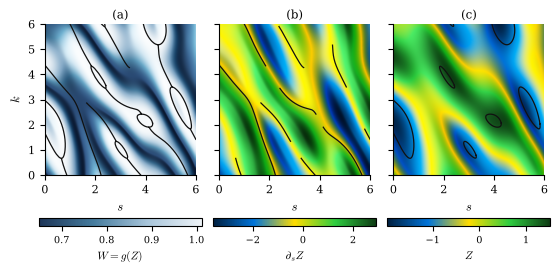

In [11]:
def masked_contours(field, weight, h):
    # pieces of the curves {field = 0} where the linear interpolation of weight is negative (NaN elsewhere), in units of s, k
    curves = []
    for c in find_contours(field, 0.0):
        p = c*h
        p[map_coordinates(weight, c.T, order=1) >= 0] = np.nan
        curves.append(p)
    return curves


def decomposition_figure(name="gauss-mix", seed=12, side=6.0, h=0.02, theta=0.0, fname="figs/airy_demo.pdf"):
    g = TRANSFORMS[name]
    F = fields_on_grid(sample_modes(seed), theta, h, s_max=side, t_max=0.0)          # one time section, t = 0
    Z, Zs, Zss = F["Z"][:, :, 0], F["Zs"][:, :, 0], F["Zss"][:, :, 0]
    W = g.g(Z)
    crest_W = masked_contours(g.dg(Z)*Zs, g.d2g(Z)*Zs**2 + g.dg(Z)*Zss, h)          # (a) from W only: d_s W = 0, d_ss W < 0
    S = masked_contours(Zs, g.dg(Z)*Zss, h)                                          # (b) d_s Z = 0, g'(Z) d_ss Z < 0
    L = [c*h for r in g.maxima for c in find_contours(Z, r)]                         # (c) Z = r, r in R_max

    sea = LinearSegmentedColormap.from_list("sea", ["#1d3557", "#457b9d", "#a8c5da", "#eef3f7"])
    field = LinearSegmentedColormap.from_list("field", ["#001f3f", "#0074d9", "#ffdc00", "#2ecc40", "#0d3a13"])
    light = LightSource(azdeg=270, altdeg=35)                                          # light along s
    exag_W = 0.6*(Z.max() - Z.min())/max(W.max() - W.min(), 1e-9)
    panels = [(W, sea, exag_W, r"$W=g(Z)$", "(a)", crest_W),
              (Zs, field, 0.6, r"$\partial_s Z$", "(b)", S),
              (Z, field, 0.6, r"$Z$", "(c)", L)]

    fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.65), sharey=True, gridspec_kw=dict(wspace=0.07))
    for ax, (V, cmap, exag, label, title, curves) in zip(axes, panels):
        rgb = light.shade(V.T, cmap=cmap, blend_mode="soft", vert_exag=exag, dx=h, dy=h, vmin=V.min(), vmax=V.max())
        ax.imshow(rgb, origin="lower", extent=[0, side, 0, side], interpolation="bilinear")
        for c in curves:
            ax.plot(c[:, 0], c[:, 1], color="#111111", lw=0.9)
        cb = fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(V.min(), V.max())), ax=ax,
                          orientation="horizontal", fraction=0.05, pad=0.21)
        cb.set_label(label, fontsize=8)
        cb.ax.tick_params(labelsize=7)
        ax.set_title(title, fontsize=8.5, pad=4)
        ax.set_xlabel("$s$")
        ax.set_xlim(0, side)
        ax.set_ylim(0, side)
        ax.set_aspect("equal")
        ax.grid(False)
    axes[0].set_ylabel("$k$")
    fig.savefig(fname)
    plt.show()


decomposition_figure()

## 4. Overview of main results (Table 1)

Table 1 compares $\overline{\mathcal H}{}^2_{N,h}$ with the Kac–Rice formula at $h=0.1$ and $h=0.05$ ($\theta=0$, $N=2000$ fields).
For the identity and $e^z$, which have no critical point, the means agree with the theory at both grid spacings: the relative
errors are $-0.2\%$ and $-0.3\%$ at $h=0.1$ ($1.4$ and $1.8$ standard errors) and $-0.1\%$ at $h=0.05$ ($0.9$ and $1.0$ standard errors).
When $g$ has critical points the error is larger: at $h=0.1$ it goes from $-2.3\%$ to $-4.4\%$ for the four non-monotone
transformations, and it is $+0.9\%$ for $z^3$; at $h=0.05$ it goes from $-1.0\%$ to $-2.7\%$, and it is $+0.4\%$ for $z^3$. So halving
$h$ halves the error: it is a meshing error of order $h$, which tends to zero with $h$, and not an error of the formula. The correction $\Delta_\theta(g)$ decreases the area for $-z^2/2$ and increases it for the last
two transformations, as predicted by its sign. For $z^3$, $g'(0)=0$ but $\mathcal R_{\max}=\emptyset$ and $\Delta_\theta(g)=0$: the level
set $\{Z=0\}$ belongs to the directional critical set but contains no directional maxima, and the formula has no extra term.

In [12]:
def run_sweep(n_fields=N_FIELDS, theta=0.0, hs=HS, A=None):
    # crest areas of the fields with seeds 80000, ... for all transformations and grid spacings: (fields, transf., h)
    areas = simulate(n_fields, 80000, theta, hs, A)
    return dict(areas=areas, hs=hs, names=NAMES, seeds=80000 + np.arange(n_fields))


# Monte Carlo run at theta = 0: N = 2000 fields, all transformations and all grid spacings
SWEEP = load_or_simulate("data/sweep_theta0_N2000.npz", run_sweep)
print(f"SWEEP: {SWEEP.shape[0]} fields x {SWEEP.shape[1]} transformations x {SWEEP.shape[2]} grid spacings")

SWEEP: 2000 fields x 7 transformations x 7 grid spacings


In [13]:
# Table 1. Change the parameters and re-run the cell: rows (subset of NAMES), grid spacings (one block of columns per h),
# direction, eigenvalues of A ((1, 1) gives the isotropic field), number of fields. Runs that are not in SWEEP are simulated
# and saved in data/ (or loaded from data/ if USE_SAVED_DATA and the run was saved before).
TABLE = dict(
    rows=["id", "exp", "z3", "quad", "cubic", "sextic", "gauss-mix"],
    hs=[0.1, 0.05],          # one block of columns (mean, s.e., rel.) per grid spacing
    theta_deg=0.0,
    a=(A1, A2),              # eigenvalues of A; (1, 1) gives the isotropic field
    N=N_FIELDS,
)


def table_runs(hs, theta_deg, a, N):
    # estimates (N, transformations, len(hs)): from SWEEP when possible, otherwise new runs saved in data/
    if theta_deg == 0 and tuple(a) == (A1, A2) and set(hs) <= set(HS) and N <= len(SWEEP):
        return SWEEP[:N][:, :, [HS.index(h) for h in hs]]
    path = f"data/table_theta{theta_deg:g}_a{a[0]:.4g}-{a[1]:.4g}_h{'-'.join(f'{h:g}' for h in hs)}_N{N}.npz"
    return load_or_simulate(path, lambda: run_sweep(N, np.radians(theta_deg), hs, matrix_A(*a)))


def make_table(rows, hs, theta_deg, a, N, tex_file="table1.tex"):
    areas = table_runs(hs, theta_deg, a, N)
    lines = []
    for name in rows:
        kr, Delta = kac_rice(name, np.radians(theta_deg), a)
        cells = [TRANSFORMS[name].tex, "$0$" if Delta == 0 else f"${Delta:.4f}$", f"${kr:.4f}$"]
        for j, h in enumerate(hs):
            x = areas[:, NAMES.index(name), j]
            mean, se = x.mean(), x.std(ddof=1)/np.sqrt(N)
            rel = 100*(mean/kr - 1)
            cells += [f"${mean:.4f}$", f"${se:.4f}$", "$0.0\\%$" if abs(rel) < 0.05 else f"${rel:.1f}\\%$"]
            print(f"{name:10s} h = {h:<5g} mean {mean:.4f}  s.e. {se:.4f}  rel. {rel:+.2f}%  ({(mean - kr)/se:+.1f} s.e.)")
        lines.append(" & ".join(cells) + r"\\")
    field = "the isotropic field" if a[0] == a[1] else r"the anisotropic field \eqref{eq:affine_A}"
    tex = "\n".join([
        r"\begin{table}[H]", r"\centering", r"\small",
        rf"\caption{{Crest surface area per unit volume, $\mathbb E\,\mathcal H^2(C^W_{{E_{{Q,T}}}})/(|Q|T)$, for {field} and "
        rf"$\theta={theta_deg:g}^\circ$: Kac--Rice value \eqref{{eq:main_crest_area_3d}} and Monte Carlo mean "
        rf"$\overline{{\mathcal H}}{{}}^2_{{N,h}}/(|Q|T)$ over $N={N}$ fields, at " + " and ".join(f"$h={h:g}$" for h in hs)
        + r", with standard error (s.e.) and relative error.}",
        r"\label{tab:airy_audit}", r"\renewcommand{\arraystretch}{1.15}", r"\setlength{\tabcolsep}{4pt}",
        r"\begin{tabular}{l|rr" + "rrr"*len(hs) + "}", r"\hline",
        "& & & " + " & ".join(rf"\multicolumn{{3}}{{c}}{{$h={h:g}$}}" for h in hs) + r"\\",
        r"Transformations $g(z)$ & $\Delta_\theta(g)$ & Kac-Rice & " + " & ".join(["mean & s.e. & rel."]*len(hs)) + r"\\",
        r"\hline", *lines, r"\hline", r"\end{tabular}", r"\end{table}"])
    with open(tex_file, "w") as f:
        f.write(tex + "\n")
    print(f"\n{tex_file}:\n{tex}")


make_table(**TABLE)

id         h = 0.1   mean 0.5430  s.e. 0.0008  rel. -0.19%  (-1.4 s.e.)
id         h = 0.05  mean 0.5434  s.e. 0.0008  rel. -0.12%  (-0.9 s.e.)
exp        h = 0.1   mean 0.5427  s.e. 0.0008  rel. -0.25%  (-1.8 s.e.)
exp        h = 0.05  mean 0.5433  s.e. 0.0008  rel. -0.14%  (-1.0 s.e.)
z3         h = 0.1   mean 0.5490  s.e. 0.0008  rel. +0.92%  (+6.4 s.e.)
z3         h = 0.05  mean 0.5462  s.e. 0.0008  rel. +0.40%  (+2.9 s.e.)


quad       h = 0.1   mean 0.9597  s.e. 0.0014  rel. -4.43%  (-32.6 s.e.)
quad       h = 0.05  mean 0.9773  s.e. 0.0014  rel. -2.68%  (-19.1 s.e.)
cubic      h = 0.1   mean 1.1323  s.e. 0.0014  rel. -2.73%  (-23.3 s.e.)
cubic      h = 0.05  mean 1.1472  s.e. 0.0014  rel. -1.45%  (-12.0 s.e.)


sextic     h = 0.1   mean 1.3507  s.e. 0.0016  rel. -2.35%  (-20.8 s.e.)
sextic     h = 0.05  mean 1.3670  s.e. 0.0016  rel. -1.17%  (-10.2 s.e.)


gauss-mix  h = 0.1   mean 1.1113  s.e. 0.0013  rel. -2.34%  (-21.2 s.e.)
gauss-mix  h = 0.05  mean 1.1262  s.e. 0.0013  rel. -1.04%  (-9.1 s.e.)

table1.tex:
\begin{table}[H]
\centering
\small
\caption{Crest surface area per unit volume, $\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})/(|Q|T)$, for the anisotropic field \eqref{eq:affine_A} and $\theta=0^\circ$: Kac--Rice value \eqref{eq:main_crest_area_3d} and Monte Carlo mean $\overline{\mathcal H}{}^2_{N,h}/(|Q|T)$ over $N=2000$ fields, at $h=0.1$ and $h=0.05$, with standard error (s.e.) and relative error.}
\label{tab:airy_audit}
\renewcommand{\arraystretch}{1.15}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{l|rrrrrrrr}
\hline
& & & \multicolumn{3}{c}{$h=0.1$} & \multicolumn{3}{c}{$h=0.05$}\\
Transformations $g(z)$ & $\Delta_\theta(g)$ & Kac-Rice & mean & s.e. & rel. & mean & s.e. & rel.\\
\hline
$z$ & $0$ & $0.5440$ & $0.5430$ & $0.0008$ & $-0.2\%$ & $0.5434$ & $0.0008$ & $-0.1\%$\\
$e^{z}$ & $0$ & $0.5440$ & $0.5427$ & $0.0008$ & $-0.3\%$ &

## 5. Reducible and irreducible errors (Figures 2 and 3)

The error of the Monte Carlo mean is the sum of two terms:
$$\overline{\mathcal H}{}^2_{N,h}-\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})
=\underbrace{\frac1N\sum_{j=1}^N\Bigl(\mathcal H^2(C_j)-\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})\Bigr)}_{\varepsilon_N}
+\underbrace{\frac1N\sum_{j=1}^N\Bigl(\widehat{\mathcal H}{}^2_h(C_j)-\mathcal H^2(C_j)\Bigr)}_{b_N(h)} .$$
The Monte Carlo error $\varepsilon_N$ is reducible: it has mean zero and standard deviation $\operatorname{sd}(\mathcal H^2(C_1))/\sqrt N$. Here the coefficient of
variation of $\mathcal H^2(C_1)$ is $5\%$ to $6\%$, so with $N=2000$ the standard deviation of $\varepsilon_N$ is about $0.13\%$ of the mean. Since the
same fields are used at every $h$, $\varepsilon_N$ does not depend on $h$: it shifts all the points of a curve in Figure 2 by the same
amount. The meshing error $b_N(h)$ is irreducible: it does not decrease with $N$, and its mean $b(h)$ depends only on $h$ and on $g$.

In [14]:
cv = SWEEP[:, :, HS.index(0.1)].std(0, ddof=1)/SWEEP[:, :, HS.index(0.1)].mean(0)
print(f"coefficient of variation of H^2(C_1): {100*cv.min():.1f}% to {100*cv.max():.1f}%;"
      f" sd of epsilon_N with N = {N_FIELDS}: about {100*cv.mean()/np.sqrt(N_FIELDS):.2f}% of the mean")

COLOR = {"id": "#2a78d6", "exp": "#008300", "z3": "#6250d6", "quad": "#eb6834", "cubic": "#1baf7a",
         "sextic": "#eda100", "gauss-mix": "#e87ba4"}
MARKER = {"id": "o", "exp": "P", "z3": "X", "quad": "s", "cubic": "^", "sextic": "D", "gauss-mix": "v"}


def plot_with_ci(ax, x, y, half_width, name, ls="-"):
    # line, hollow markers and 95% confidence intervals drawn on top with wide caps
    ax.plot(x, y, ls=ls, color=COLOR[name], lw=1.1, zorder=2)
    ax.plot(x, y, MARKER[name], color=COLOR[name], ms=3.4, mfc="white", mew=1.0, ls="none", zorder=3)
    ax.errorbar(x, y, yerr=half_width, fmt="none", ecolor=COLOR[name], elinewidth=1.5, capsize=4, capthick=1.4, zorder=4)


def legend_handle(name, ls="-"):
    return Line2D([], [], color=COLOR[name], lw=1.1, ls=ls, marker=MARKER[name], ms=3.4, mfc="white", mew=1.0)

coefficient of variation of H^2(C_1): 5.1% to 6.4%; sd of epsilon_N with N = 2000: about 0.13% of the mean


**Figure 2** shows the ratio $\overline{\mathcal H}{}^2_{N,h}/\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})$ between the Monte Carlo mean and the Kac–Rice value,
as a function of the grid spacing $h$ ($\theta=0$, same $N=2000$ fields at every $h$, $95\%$ confidence intervals). For the identity and $e^z$
it is $0.985$ and $0.982$ at $h=0.4$, and reaches $1$ within the confidence intervals at $h=0.05$ ($0.9988$ and $0.9986$, half-width $0.0028$).
For the five transformations with critical points the ratio converges to $1$ more slowly.

id         ratio at h = 0.4: 0.9853, at h = 0.05: 0.9988 (95% half-width 0.0028)
exp        ratio at h = 0.4: 0.9823, at h = 0.05: 0.9986 (95% half-width 0.0028)
z3         ratio at h = 0.4: 1.0459, at h = 0.05: 1.0040 (95% half-width 0.0028)
quad       ratio at h = 0.4: 0.8700, at h = 0.05: 0.9732 (95% half-width 0.0027)
cubic      ratio at h = 0.4: 0.8924, at h = 0.05: 0.9855 (95% half-width 0.0024)
sextic     ratio at h = 0.4: 0.8769, at h = 0.05: 0.9883 (95% half-width 0.0022)
gauss-mix  ratio at h = 0.4: 0.8703, at h = 0.05: 0.9896 (95% half-width 0.0022)


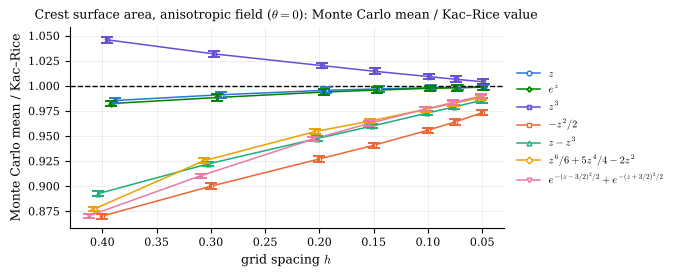

In [15]:
fig, ax = plt.subplots(figsize=(5.6, 2.6))
for i, name in enumerate(NAMES):
    x = SWEEP[:, NAMES.index(name), :]/KR[name]
    ratio, se = x.mean(0), x.std(0, ddof=1)/np.sqrt(N_FIELDS)
    plot_with_ci(ax, np.array(HS)*(1 + 0.01*(i - 3)), ratio, 1.96*se, name)
    print(f"{name:10s} ratio at h = 0.4: {ratio[0]:.4f}, at h = 0.05: {ratio[-1]:.4f} (95% half-width {1.96*se[-1]:.4f})")
ax.axhline(1.0, color="k", ls="--", lw=1.0)
ax.invert_xaxis()
ax.set_xlabel("grid spacing $h$")
ax.set_ylabel("Monte Carlo mean / Kac–Rice")
ax.set_title(r"Crest surface area, anisotropic field ($\theta=0$): Monte Carlo mean / Kac–Rice value")
ax.legend([legend_handle(n) for n in NAMES], [TRANSFORMS[n].tex for n in NAMES], loc="center left",
          bbox_to_anchor=(1.01, 0.5), frameon=False, handlelength=2.2)
fig.savefig("figs/airy_hsweep.pdf")
plt.show()

**Figure 3** illustrates the order of $b(h)$ in $h$. To remove $\varepsilon_N$, for $g\neq\mathrm{id}$ we plot the paired difference with the identity,
$$e_g(h)=\frac1N\sum_{j=1}^N\Bigl(\widehat{\mathcal H}{}^2_h\bigl(C^{g(Z_j)}_{E_{Q,T}}\bigr)-\widehat{\mathcal H}{}^2_h\bigl(C^{Z_j}_{E_{Q,T}}\bigr)\Bigr)
-\Bigl(\mathbb E\,\mathcal H^2\bigl(C^{g(Z)}_{E_{Q,T}}\bigr)-\mathbb E\,\mathcal H^2\bigl(C^{Z}_{E_{Q,T}}\bigr)\Bigr).$$
For $e^z$ and $z^3$ the crest surfaces of $g(Z_j)$ and $Z_j$ are the same set, so the Monte Carlo errors cancel exactly and $e_g(h)$ is the
difference of the two meshing errors. For the four non-monotone transformations the meshing error of $g$ is much larger than that of the
identity, and $e_g(h)$ is close to it. For the identity we plot $\overline{\mathcal H}{}^2_{N,h}-\overline{\mathcal H}{}^2_{N,h/2}$ on nested grids,
which has the same order in $h$ as the error. The figure shows two regimes. When $\mathcal C_g=\emptyset$, the zero set of
$\partial_sW_\theta=g'(Z_\theta)\partial_sZ_\theta$ is the regular surface $\{\partial_sZ_\theta=0\}$, and the error is of order $h^2$: the slope is $1.94$
for the identity and $1.95$ for $e^z$ on the last pair of grids. When $\mathcal C_g\neq\emptyset$, the zero set of $\partial_sW_\theta$ also contains
the level sets $\{Z_\theta=r\}$, $r\in\mathcal C_g$, which meet $\{\partial_sZ_\theta=0\}$ along the coincidence sets $\mathcal I_r$. Near them the
gradient of $\partial_sW_\theta$ vanishes and the mesh is less accurate. The error is then of order $h$: the slopes are between $0.73$ and $1.21$.
For $-z^2/2$ the slope ($0.73$) is still below one: on these grids its error has not yet reached the asymptotic order $h$.

id         log-log slope 1.94 (last pair of grids 1.87)
exp        log-log slope 1.47 (last pair of grids 1.95)
z3         log-log slope 1.17 (last pair of grids 1.06)
quad       log-log slope 0.73 (last pair of grids 0.73)
cubic      log-log slope 0.95 (last pair of grids 0.94)
sextic     log-log slope 1.09 (last pair of grids 1.03)
gauss-mix  log-log slope 1.21 (last pair of grids 1.21)


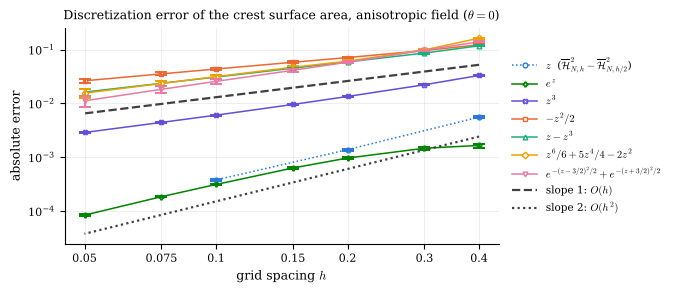

In [16]:
h = np.array(HS)
area = lambda name: SWEEP[:, NAMES.index(name), :]
fig, ax = plt.subplots(figsize=(5.6, 2.8))
handles, labels, err = [], [], {}
for name in NAMES:
    if name == "id":                                   # successive differences on nested grids h, h/2
        hx = np.array([0.4, 0.2, 0.1])
        d = np.stack([area(name)[:, HS.index(x)] - area(name)[:, HS.index(x/2)] for x in hx], axis=1)
        label, ls = TRANSFORMS[name].tex + r"  ($\overline{\mathcal{H}}^2_{N,h}-\overline{\mathcal{H}}^2_{N,h/2}$)", ":"
    else:                                              # paired difference with the identity, e_g(h)
        hx = h
        d = area(name) - area("id") - (KR[name] - KR["id"])
        label, ls = TRANSFORMS[name].tex, "-"
    mean, se = d.mean(0), d.std(0, ddof=1)/np.sqrt(N_FIELDS)
    err[name] = np.abs(mean)
    lower = np.minimum(1.96*se, 0.95*np.abs(mean))     # keep the interval positive on the log axis
    plot_with_ci(ax, hx, np.abs(mean), [lower, 1.96*se], name, ls)
    handles.append(legend_handle(name, ls))
    labels.append(label)
    slope_all = np.polyfit(np.log(hx), np.log(np.abs(mean)), 1)[0]
    slope_last = np.log(abs(mean[-1]/mean[-2]))/np.log(hx[-1]/hx[-2])
    print(f"{name:10s} log-log slope {slope_all:.2f} (last pair of grids {slope_last:.2f})")
level1 = np.exp(np.mean([np.log(err[n][HS.index(0.2)]) for n in ("quad", "cubic", "sextic", "gauss-mix")]))
handles += ax.plot(h, 0.42*level1*(h/0.2), color="0.25", lw=1.6, ls="--")
handles += ax.plot(h, 0.45*err["exp"][-1]*(h/0.05)**2, color="0.25", lw=1.6, ls=(0, (1, 1.5)))
labels += [r"slope 1: $O(h)$", r"slope 2: $O(h^2)$"]
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(HS)
ax.set_xticklabels([f"{x:g}" for x in HS])
ax.minorticks_off()
ax.set_xlabel("grid spacing $h$")
ax.set_ylabel("absolute error")
ax.set_title(r"Discretization error of the crest surface area, anisotropic field ($\theta=0$)")
ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, handlelength=2.4)
fig.savefig("figs/airy_error.pdf")
plt.show()

## 6. Dependence on the direction $\theta$ (Figure 4)

The leading term of the Kac–Rice formula is $\mathcal E_3(\Sigma_{\nabla\partial_sZ_\theta})/(\pi\sqrt{c_{11}})$, and $c_{11}=|Au_\theta|^2$ is largest for
$u_\theta=e_1$ ($c_{11}=a_1^2$) and smallest for $u_\theta=e_2$ ($c_{11}=a_2^2$). On a line in the direction $u_\theta$, the Rice formula gives
$\frac1{2\pi}\sqrt{\widetilde m_{4,0,0}/\widetilde m_{2,0,0}}=\sqrt{3c_{11}}/(2\pi)$ local maxima per unit length: the field changes fastest along the
stretched direction $e_1$, so it has the most maxima, and the largest crest area, in this direction, and the fewest in the orthogonal
direction $e_2$. The reflection across $e_1$ leaves $A$ unchanged and only changes the sign of $c_{12}$, so $\mathbb E\,\mathcal H^2(C^W_{E_{Q,T}})$
is symmetric around $\theta=\phi_0$. For the isotropic field ($A=I_2$) the expected area does not depend on $\theta$.

Figure 4 compares the anisotropic field with the isotropic field, on the same $120$ fields (same seeds) for the $12$ directions
$\theta=0^\circ,15^\circ,\dots,165^\circ$; the Monte Carlo means are computed at $h=0.05$, and $-z^2/2$ is not shown.

In [17]:
SHOWN = ["id", "cubic", "sextic", "gauss-mix"]          # z, e^z, z^3 share the Kac-Rice value; -z^2/2 is not shown
THETA_DEG = np.arange(0, 180, 15)                      # Monte Carlo directions
N_DIR = 120                                            # fields, seeds 90000, 90001, ...
THETA_CURVE = np.arange(0, 180.01, 2.5)                # Kac-Rice curves (same random numbers for Delta at every theta)

KR_CURVE = {n: np.array([kac_rice(n, np.radians(d), n_mc=2_000_000, seed=7)[0] for d in THETA_CURVE]) for n in SHOWN}
KR_ISO = {n: kac_rice(n, a=(1.0, 1.0))[0] for n in SHOWN}
for n in SHOWN:
    c = KR_CURVE[n]
    print(f"{n:10s} anisotropic: max {c.max():.4f} at {THETA_CURVE[c.argmax()]:.1f} deg, min {c.min():.4f} at "
          f"{THETA_CURVE[c.argmin()]:.1f} deg, ratio {c.max()/c.min():.2f};  isotropic: {KR_ISO[n]:.4f}")

id         anisotropic: max 0.5512 at 30.0 deg, min 0.4226 at 120.0 deg, ratio 1.30;  isotropic: 0.4416
cubic      anisotropic: max 1.1712 at 30.0 deg, min 1.0426 at 120.0 deg, ratio 1.12;  isotropic: 1.0025
sextic     anisotropic: max 1.3923 at 30.0 deg, min 1.2224 at 120.0 deg, ratio 1.14;  isotropic: 1.1840
gauss-mix  anisotropic: max 1.1466 at 30.0 deg, min 0.9933 at 120.0 deg, ratio 1.15;  isotropic: 0.9690


In [18]:
def run_directions(A, n_fields=N_DIR, h=0.05):
    # crest areas at h = 0.05 of the same fields (seeds 90000, ...) for the 12 directions: (fields, directions, transf.)
    areas = np.stack([simulate(n_fields, 90000, np.radians(d), [h], A)[:, :, 0] for d in THETA_DEG], axis=1)
    return dict(areas=areas, thetas_deg=THETA_DEG, h=h, names=NAMES, seeds=90000 + np.arange(n_fields))


DIR_ANISO = load_or_simulate("data/direction_aniso_h0.05_N120.npz", lambda: run_directions(matrix_A()))
DIR_ISO = load_or_simulate("data/direction_iso_h0.05_N120.npz", lambda: run_directions(np.eye(2)))
print(f"DIR_ANISO, DIR_ISO: {DIR_ANISO.shape[0]} fields x {DIR_ANISO.shape[1]} directions x {DIR_ANISO.shape[2]} transformations")

DIR_ANISO, DIR_ISO: 120 fields x 12 directions x 7 transformations


**Figure 4.** For the anisotropic field (left), all the Kac–Rice curves have their maximum at $\theta=30^\circ$ ($e_1$) and their minimum at
$\theta=120^\circ$, in the direction $e_2$ orthogonal to the stretching. The ratio between the maximum and the minimum is $1.30$ for the
monotone transformations, and smaller for the other three ($1.12$ to $1.15$), because their level term does not depend on $\theta$.
The Monte Carlo means follow the shape of the curves, with the minimum at $\theta=120^\circ$ for every transformation. For the monotone
transformations they agree with the Kac–Rice values within $2.9$ standard errors at every $\theta$ (the errors at nearby directions are
correlated, since the fields are the same). For the other three they are $1.2\%$ to $1.5\%$ below the curves on average over $\theta$:
this is the meshing error at $h=0.05$, of the same size as in Table 1. For the isotropic field (right) the Kac–Rice curves are flat.
The Monte Carlo means are flat too: over the $12$ directions the largest and the smallest mean differ by at most $1.8\%$, against $13\%$
to $27\%$ for the anisotropic field, and the means of the non-monotone transformations show the same offset due to the meshing error.

aniso id         min at 120 deg, mean offset +0.4%, max |z| 2.9, spread 26.5%
aniso cubic      min at 120 deg, mean offset -1.5%, max |z| 3.8, spread 13.2%
aniso sextic     min at 120 deg, mean offset -1.2%, max |z| 4.2, spread 13.8%
aniso gauss-mix  min at 120 deg, mean offset -1.4%, max |z| 3.5, spread 14.0%
iso   id         min at 105 deg, mean offset -0.2%, max |z| 1.7, spread 1.7%
iso   cubic      min at 165 deg, mean offset -1.6%, max |z| 4.7, spread 1.8%
iso   sextic     min at 165 deg, mean offset -1.1%, max |z| 3.9, spread 1.4%
iso   gauss-mix  min at  15 deg, mean offset -1.6%, max |z| 3.6, spread 0.7%


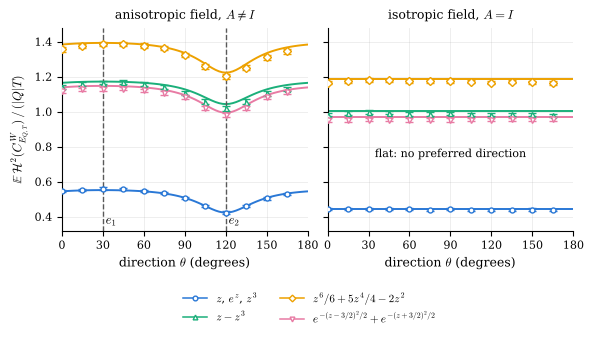

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.5), sharey=True, gridspec_kw=dict(wspace=0.08))
fig.subplots_adjust(bottom=0.30)
for ax, data, title, aniso in ((axes[0], DIR_ANISO, r"anisotropic field, $A\neq I$", True),
                               (axes[1], DIR_ISO, r"isotropic field, $A=I$", False)):
    for n in SHOWN:
        curve = KR_CURVE[n] if aniso else np.full(len(THETA_CURVE), KR_ISO[n])
        ax.plot(THETA_CURVE, curve, color=COLOR[n], lw=1.4, zorder=2)
        x = data[:, :, NAMES.index(n)]
        mean, se = x.mean(0), x.std(0, ddof=1)/np.sqrt(N_DIR)
        ax.errorbar(THETA_DEG, mean, yerr=1.96*se, fmt=MARKER[n], ms=3.6, color=COLOR[n], mfc="white", mew=1.0,
                    elinewidth=1.3, capsize=3, capthick=1.2, ls="none", zorder=3)
        kr = np.interp(THETA_DEG, THETA_CURVE, curve)
        print(f"{'aniso' if aniso else 'iso':5s} {n:10s} min at {THETA_DEG[mean.argmin()]:3d} deg, mean offset "
              f"{100*np.mean(mean/kr - 1):+.1f}%, max |z| {np.max(np.abs(mean - kr)/se):.1f}, "
              f"spread {100*(mean.max() - mean.min())/mean.mean():.1f}%")
    ax.set_xlim(0, 180)
    ax.set_xticks(range(0, 181, 30))
    ax.set_xlabel(r"direction $\theta$ (degrees)")
    ax.set_title(title, fontsize=9)
for x, label in ((30, r"$e_1$"), (120, r"$e_2$")):
    axes[0].axvline(x, color="0.35", lw=1.0, ls="--")
    axes[0].text(x + 2, 0.34, label, va="bottom", fontsize=9)
axes[1].text(90, 0.74, "flat: no preferred direction", ha="center", fontsize=8)
axes[0].set_ylim(0.32, 1.48)
axes[0].set_ylabel(r"$\mathbb{E}\,\mathcal{H}^2(C^W_{E_{Q,T}})\,/\,(|Q|T)$")
fig.legend([legend_handle(n) for n in SHOWN], [r"$z$, $e^z$, $z^3$"] + [TRANSFORMS[n].tex for n in SHOWN[1:]],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0), frameon=False, handlelength=2.2, fontsize=8)
fig.savefig("figs/airy_angle.pdf")
plt.show()